# tips 기초통계·시각화
서문성빈. 수업 Question 원문이 확인되지 않아 해당 문항의 정답이라고 주장하지 않는다. 본 노트북의 질문은 자체 분석 점검용이다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
tips=pd.read_csv('tips.csv')
tips['tip_pct']=tips.tip/tips.total_bill*100
print(tips[['total_bill','tip','size','tip_pct']].describe().to_string())
print('결측값',tips.isna().sum().to_dict())
print('상관계수',tips.total_bill.corr(tips.tip))
print('일행별 평균 팁 비율',tips.tip_pct.mean())
print('금액가중 팁 비율',100*tips.tip.sum()/tips.total_bill.sum())

       total_bill         tip        size     tip_pct
count  244.000000  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672   16.080258
std      8.902412    1.383638    0.951100    6.107220
min      3.070000    1.000000    1.000000    3.563814
25%     13.347500    2.000000    2.000000   12.912736
50%     17.795000    2.900000    2.000000   15.476977
75%     24.127500    3.562500    3.000000   19.147549
max     50.810000   10.000000    6.000000   71.034483
결측값 {'total_bill': 0, 'tip': 0, 'sex': 0, 'smoker': 0, 'day': 0, 'time': 0, 'size': 0, 'tip_pct': 0}
상관계수 0.6757341092113645
일행별 평균 팁 비율 16.08025817225047
금액가중 팁 비율 15.153580224410026


      parties  guests    sales    tip_pct
day                                      
Fri        19      40   325.88  16.991303
Sat        87     219  1778.40  15.315172
Sun        76     216  1627.16  16.689729
Thur       62     152  1096.33  16.127563


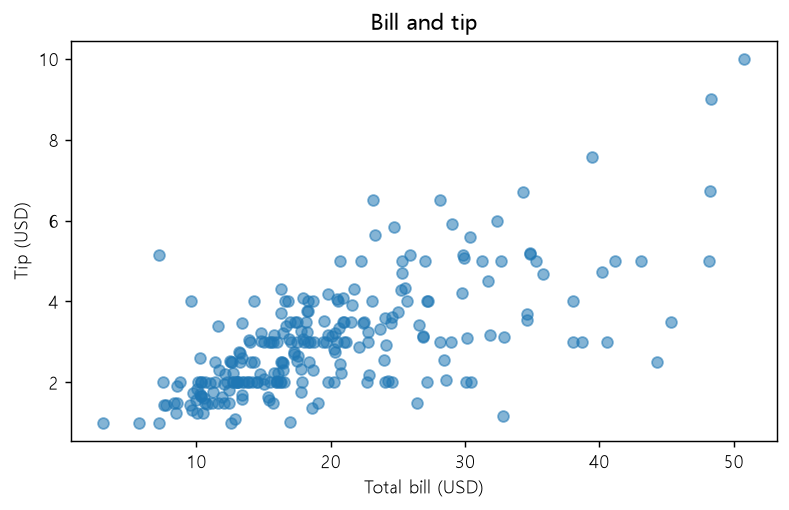

In [2]:
summary=tips.groupby('day').agg(parties=('total_bill','size'),guests=('size','sum'),sales=('total_bill','sum'),tip_pct=('tip_pct','mean'))
print(summary.to_string())
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(tips.total_bill,tips.tip,alpha=.55)
ax.set(xlabel='Total bill (USD)',ylabel='Tip (USD)',title='Bill and tip')

size()는 일행 수, size 열의 sum()은 사람 수다. 평균 비율과 합계 비율은 다르다. 관찰된 상관관계를 인과관계로 해석하지 않는다. 고액 계산서는 실제 값일 수 있어 근거 없이 제거하지 않는다.

남은 요건: 수업 Question 원문과 답변, 본인 GitHub 저장소 업로드, 학교 제출 통로 확인.